# TechStore — Sales Team Performance Dashboard

Executive SQL dashboard built for TechStore's leadership review, evaluating each sales representative's revenue, target attainment, category mix, top customer concentration, cancellation risk, regional product champions, and Jan–Mar 2024 monthly trajectory.

The raw Portuguese seed (`SQL/seed_techstore.sql`) is loaded into an in-memory DuckDB instance, and an English semantic view layer (`SQL/views_en.sql`) maps table names, columns, and categorical labels for reporting.

In [1]:
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt
import numpy as np

con = duckdb.connect()
con.execute(Path("SQL/seed_techstore.sql").read_text(encoding="utf-8"))
con.execute(Path("SQL/views_en.sql").read_text(encoding="utf-8"))

DOCS_DIR = Path("docs")
DOCS_DIR.mkdir(exist_ok=True)


def sql(query: str):
    """Run a SQL query against the in-memory TechStore database and return a DataFrame."""
    return con.sql(query).df()


sql("""
SELECT table_name, table_type
FROM information_schema.tables
WHERE table_schema = 'main'
ORDER BY table_type, table_name;
""")

,table_name,table_type
0,clientes,BASE TABLE
1,itens_pedido,BASE TABLE
2,pedidos,BASE TABLE
3,produtos,BASE TABLE
4,vendedores,BASE TABLE
5,customers,VIEW
6,order_items,VIEW
7,orders,VIEW
8,products,VIEW
9,sales_reps,VIEW


## 1. Overall Sales Rep Ranking

**Business question:** Who are TechStore's top sales reps and how close are they to their target?

Uses `LEFT JOIN` (so reps with zero delivered orders would still appear) and `RANK() OVER (ORDER BY ...)` to rank all 7 reps by delivered revenue, alongside delivered order count, average ticket, monthly target, and cumulative attainment percentage.

In [2]:
df_ranking = sql("""
SELECT
    RANK() OVER (ORDER BY COALESCE(SUM(o.total_amount), 0) DESC) AS rank,
    r.name AS sales_rep,
    r.region,
    COUNT(o.id) AS delivered_orders,
    COALESCE(SUM(o.total_amount), 0) AS revenue,
    ROUND(AVG(o.total_amount), 2) AS avg_ticket,
    r.monthly_target,
    ROUND(100.0 * COALESCE(SUM(o.total_amount), 0) / r.monthly_target, 1) AS pct_of_monthly_target
FROM sales_reps r
LEFT JOIN orders o
    ON o.sales_rep_id = r.id
    AND o.status = 'Delivered'
GROUP BY r.id, r.name, r.region, r.monthly_target
ORDER BY revenue DESC;
""")
df_ranking

,rank,sales_rep,region,delivered_orders,revenue,avg_ticket,monthly_target,pct_of_monthly_target
0,1,Ricardo Mendes,Southeast,26,69300.3,2665.40,60000.0,115.5
1,2,Fernanda Lima,South,21,61382.6,2922.98,45000.0,136.4
2,3,Juliana Rocha,Northeast,20,59480.0,2974.00,40000.0,148.7
3,4,Carlos Eduardo,Southeast,19,53233.7,2801.77,55000.0,96.8
4,5,Marcos Santana,Northeast,19,48881.9,2572.73,35000.0,139.7
5,6,Amanda Torres,North,8,19329.0,2416.13,30000.0,64.4
6,7,Bruno Alves,Center-West,8,14682.9,1835.36,35000.0,42.0


**Takeaway:**
- **Ricardo Mendes** (BRL 69,300.30, 26 orders), **Fernanda Lima** (BRL 61,382.60, 21 orders), and **Juliana Rocha** (BRL 59,480.00, 20 orders) lead total delivered revenue.
- **Juliana Rocha** posts the highest average ticket (**BRL 2,974.00**) and highest target ratio (**148.7%**), followed by **Marcos Santana** (**139.7%**) and **Fernanda Lima** (**136.4%**).
- Note that `pct_of_monthly_target` compares *cumulative* delivered revenue across the dataset window (Dec 2023 – Mar 15, 2024) against a single month's target. Even on a cumulative basis, **Amanda Torres** (64.4%) and **Bruno Alves** (42.0%) have not yet cleared one month of quota.

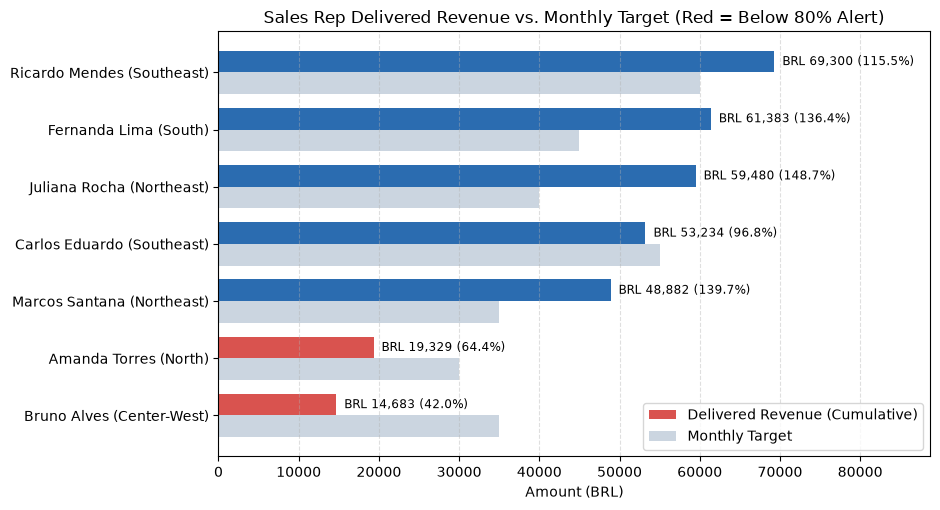

In [3]:
plot_df = df_ranking.sort_values("revenue", ascending=True)
y = np.arange(len(plot_df))
height = 0.38

fig, ax = plt.subplots(figsize=(9.5, 5.2))
colors = [
    "#d9534f" if pct < 80 else "#2b6cb0"
    for pct in plot_df["pct_of_monthly_target"]
]

bars_rev = ax.barh(y + height / 2, plot_df["revenue"], height, color=colors, label="Delivered Revenue (Cumulative)")
bars_tgt = ax.barh(y - height / 2, plot_df["monthly_target"], height, color="#cbd5e0", label="Monthly Target")

for bar, pct in zip(bars_rev, plot_df["pct_of_monthly_target"]):
    w = bar.get_width()
    ax.text(w + 1000, bar.get_y() + bar.get_height() / 2, f"BRL {w:,.0f} ({pct:.1f}%)", va="center", fontsize=8.5)

ax.set_yticks(y)
ax.set_yticklabels([f"{n} ({r})" for n, r in zip(plot_df["sales_rep"], plot_df["region"])])
ax.set_xlabel("Amount (BRL)")
ax.set_title("Sales Rep Delivered Revenue vs. Monthly Target (Red = Below 80% Alert)")
ax.set_xlim(0, plot_df["revenue"].max() * 1.28)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(DOCS_DIR / "rep_ranking_vs_target.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Category Mix for Top 3 Sales Reps

**Business question:** Which product categories drive revenue for our top 3 reps?

Uses a `top3` CTE to isolate the highest-grossing reps, then joins `orders`, `order_items`, and `products` to aggregate units sold and item-level revenue per category.

In [4]:
sql("""
WITH top3 AS (
    SELECT r.id, r.name
    FROM sales_reps r
    JOIN orders o ON o.sales_rep_id = r.id AND o.status = 'Delivered'
    GROUP BY r.id, r.name
    ORDER BY SUM(o.total_amount) DESC
    LIMIT 3
)
SELECT
    r.name AS sales_rep,
    p.category,
    SUM(oi.quantity) AS units_sold,
    SUM(oi.quantity * oi.unit_price) AS revenue
FROM top3 r
JOIN orders o ON o.sales_rep_id = r.id AND o.status = 'Delivered'
JOIN order_items oi ON oi.order_id = o.id
JOIN products p ON p.id = oi.product_id
GROUP BY r.name, p.category
ORDER BY r.name, revenue DESC;
""")

,sales_rep,category,units_sold,revenue
0,Fernanda Lima,Laptops,8.0,32195.6
1,Fernanda Lima,Smartphones,9.0,15891.0
2,Fernanda Lima,Tablets,3.0,6597.0
3,Fernanda Lima,Monitors,2.0,5798.0
4,Fernanda Lima,Accessories,3.0,569.7
5,Juliana Rocha,Laptops,4.0,24396.0
6,Juliana Rocha,Smartphones,10.0,20990.0
7,Juliana Rocha,Tablets,4.0,8296.0
8,Juliana Rocha,Monitors,2.0,5798.0
9,Ricardo Mendes,Laptops,7.0,34795.7


**Takeaway:**
- **Laptops** is the #1 revenue driver for all three leaders: Ricardo Mendes (BRL 34,795.70), Fernanda Lima (BRL 32,195.60), and Juliana Rocha (BRL 24,396.00).
- **Smartphones** ranks #2 for all three, with Juliana Rocha generating BRL 20,990.00 across 10 units — nearly matching her Laptop revenue.
- **Cross-sell gap:** Accessories carry TechStore's highest gross margin (~56%), yet Juliana Rocha has zero delivered Accessory items and Fernanda Lima only 3 units (BRL 569.70), compared with Ricardo Mendes's 15 units (BRL 1,918.50).

## 3. Top 5 Customers per Sales Rep

**Business question:** Who are each rep's 5 largest accounts, and how concentrated is their book of business?

Uses `ROW_NUMBER() OVER (PARTITION BY r.id ORDER BY SUM(o.total_amount) DESC)` inside a CTE to keep up to 5 top customers per rep.

In [5]:
sql("""
WITH ranked_customers AS (
    SELECT
        r.name AS sales_rep,
        c.name AS customer,
        c.segment,
        SUM(o.total_amount) AS total_spent,
        COUNT(o.id) AS order_count,
        ROW_NUMBER() OVER (
            PARTITION BY r.id
            ORDER BY SUM(o.total_amount) DESC
        ) AS rn
    FROM orders o
    JOIN sales_reps r ON r.id = o.sales_rep_id
    JOIN customers c ON c.id = o.customer_id
    WHERE o.status = 'Delivered'
    GROUP BY r.id, r.name, c.id, c.name, c.segment
)
SELECT sales_rep, customer, segment, total_spent, order_count
FROM ranked_customers
WHERE rn <= 5
ORDER BY sales_rep, total_spent DESC;
""")

,sales_rep,customer,segment,total_spent,order_count
0,Amanda Torres,Prefeitura Regional AM,Government,16993.0,7
1,Amanda Torres,Governo RJ Digital,Government,2336.0,1
2,Bruno Alves,Thiago Rocha,Retail,7596.0,4
3,Bruno Alves,Camila Santos,Retail,7086.9,4
4,Carlos Eduardo,InfoTech Solutions,Corporate,15798.0,2
5,Carlos Eduardo,Rafael Mendes,Retail,7898.9,2
6,Carlos Eduardo,Empresa Digital SP,Corporate,7897.0,3
7,Carlos Eduardo,Carlos Pereira,Retail,7796.0,4
8,Carlos Eduardo,Sandra Lima,Retail,5697.9,3
9,Fernanda Lima,Tech Solutions LTDA,Corporate,22196.8,5


**Takeaway:**
- **Severe account concentration in underperforming territories:** Both **Amanda Torres** (North) and **Bruno Alves** (Center-West) have only **2 delivered customers** each. Amanda depends on `Prefeitura Regional AM` for **87.9%** of her revenue (BRL 16,993.00 across 7 orders), while Bruno serves only 2 Retail accounts (`Thiago Rocha` and `Camila Santos`) with zero Corporate or Government clients.
- By contrast, the top 5 reps all balance multiple segments, anchored by high-value B2B/Gov accounts (`Tech Solutions LTDA` at BRL 22,196.80, `Prefeitura de Recife` at BRL 20,295.00, `DataCorp SA` at BRL 16,384.80, `InfoTech Solutions` at BRL 15,798.00).

## 4. Cancellation Rate by Sales Rep

**Business question:** Which reps are losing the most sales to cancellations, and who crosses the 10% red-zone threshold?

First we inspect the full team breakdown, then apply `HAVING` to isolate reps above the 10% alert threshold.

In [6]:
df_cancel = sql("""
SELECT
    r.name AS sales_rep,
    COUNT(o.id) AS total_orders,
    SUM(CASE WHEN o.status = 'Cancelled' THEN 1 ELSE 0 END) AS cancelled_orders,
    ROUND(
        100.0 * SUM(CASE WHEN o.status = 'Cancelled' THEN 1 ELSE 0 END) / COUNT(o.id),
        1
    ) AS cancellation_rate_pct,
    SUM(CASE WHEN o.status = 'Cancelled' THEN o.total_amount ELSE 0 END) AS lost_revenue
FROM sales_reps r
JOIN orders o ON o.sales_rep_id = r.id
GROUP BY r.id, r.name
ORDER BY cancellation_rate_pct DESC, lost_revenue DESC;
""")
df_cancel

,sales_rep,total_orders,cancelled_orders,cancellation_rate_pct,lost_revenue
0,Bruno Alves,14,2.0,14.3,4482.1
1,Carlos Eduardo,28,3.0,10.7,13378.0
2,Ricardo Mendes,36,3.0,8.3,4997.9
3,Fernanda Lima,28,2.0,7.1,4788.9
4,Juliana Rocha,28,2.0,7.1,1293.1
5,Amanda Torres,10,0.0,0.0,0.0
6,Marcos Santana,22,0.0,0.0,0.0


In [7]:
# Red-zone alert: reps with cancellation rate strictly above 10%
sql("""
SELECT
    r.name AS sales_rep,
    COUNT(o.id) AS total_orders,
    SUM(CASE WHEN o.status = 'Cancelled' THEN 1 ELSE 0 END) AS cancelled_orders,
    ROUND(
        100.0 * SUM(CASE WHEN o.status = 'Cancelled' THEN 1 ELSE 0 END) / COUNT(o.id),
        1
    ) AS cancellation_rate_pct,
    SUM(CASE WHEN o.status = 'Cancelled' THEN o.total_amount ELSE 0 END) AS lost_revenue
FROM sales_reps r
JOIN orders o ON o.sales_rep_id = r.id
GROUP BY r.id, r.name
HAVING ROUND(
    100.0 * SUM(CASE WHEN o.status = 'Cancelled' THEN 1 ELSE 0 END) / COUNT(o.id),
    1
) > 10
ORDER BY cancellation_rate_pct DESC;
""")

,sales_rep,total_orders,cancelled_orders,cancellation_rate_pct,lost_revenue
0,Bruno Alves,14,2.0,14.3,4482.1
1,Carlos Eduardo,28,3.0,10.7,13378.0


**Takeaway:**
- **Two reps exceed the 10% red-zone threshold:**
  - **Bruno Alves:** **14.3%** cancellation rate (2 of 14 orders, BRL 4,482.10 lost).
  - **Carlos Eduardo:** **10.7%** cancellation rate (3 of 28 orders, **BRL 13,378.00 lost** — **46.2%** of TechStore's entire BRL 28,940.00 cancelled revenue).
- **Marcos Santana** (22 orders) and **Amanda Torres** (10 orders) maintain **0.0%** cancellations.

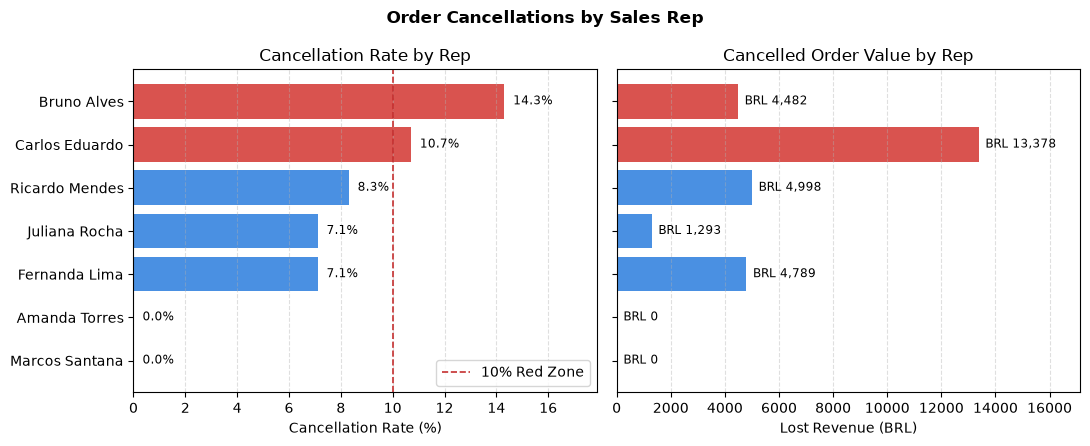

In [8]:
plot_c = df_cancel.sort_values("cancellation_rate_pct", ascending=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

bar_colors = ["#d9534f" if r > 10 else "#4a90e2" for r in plot_c["cancellation_rate_pct"]]
ax1.barh(plot_c["sales_rep"], plot_c["cancellation_rate_pct"], color=bar_colors)
ax1.axvline(10, color="#c53030", linestyle="--", linewidth=1.2, label="10% Red Zone")
for i, v in enumerate(plot_c["cancellation_rate_pct"]):
    ax1.text(v + 0.35, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax1.set_xlabel("Cancellation Rate (%)")
ax1.set_title("Cancellation Rate by Rep")
ax1.set_xlim(0, plot_c["cancellation_rate_pct"].max() * 1.25)
ax1.grid(axis="x", linestyle="--", alpha=0.4)
ax1.legend(loc="lower right")

ax2.barh(plot_c["sales_rep"], plot_c["lost_revenue"], color=bar_colors)
for i, v in enumerate(plot_c["lost_revenue"]):
    ax2.text(v + 250, i, f"BRL {v:,.0f}", va="center", fontsize=8.5)
ax2.set_xlabel("Lost Revenue (BRL)")
ax2.set_title("Cancelled Order Value by Rep")
ax2.set_xlim(0, plot_c["lost_revenue"].max() * 1.28)
ax2.grid(axis="x", linestyle="--", alpha=0.4)

fig.suptitle("Order Cancellations by Sales Rep", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(DOCS_DIR / "cancellations_by_rep.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Top 3 Champion Products by Region

**Business question:** Which 3 products generate the most revenue in each region?

Uses `ROW_NUMBER() OVER (PARTITION BY r.region ORDER BY SUM(oi.quantity * oi.unit_price) DESC)` to rank products within each territory.

In [9]:
sql("""
WITH ranked AS (
    SELECT
        r.region,
        p.name AS product,
        p.category,
        SUM(oi.quantity) AS units_sold,
        SUM(oi.quantity * oi.unit_price) AS revenue,
        ROW_NUMBER() OVER (
            PARTITION BY r.region
            ORDER BY SUM(oi.quantity * oi.unit_price) DESC
        ) AS rn
    FROM order_items oi
    JOIN orders o ON o.id = oi.order_id
    JOIN products p ON p.id = oi.product_id
    JOIN sales_reps r ON r.id = o.sales_rep_id
    WHERE o.status = 'Delivered'
    GROUP BY r.region, p.id, p.name, p.category
)
SELECT region, product, category, units_sold, revenue
FROM ranked
WHERE rn <= 3
ORDER BY region, revenue DESC;
""")

,region,product,category,units_sold,revenue
0,Center-West,Workstation W3,Laptops,2.0,5198.0
1,Center-West,"Tablet Pro 12""",Tablets,2.0,3398.0
2,Center-West,"Tablet Air 10""",Tablets,1.0,2199.0
3,North,"Tablet Air 10""",Tablets,2.0,4398.0
4,North,MacStation Desktop,Laptops,1.0,4299.0
5,North,"Monitor UltraWide 34""",Monitors,1.0,2899.0
6,Northeast,Smartphone Galaxy Ultra,Smartphones,7.0,23093.0
7,Northeast,MacStation Desktop,Laptops,4.0,17196.0
8,Northeast,Notebook Gamer Z5,Laptops,2.0,15798.0
9,South,Notebook Pro X1,Laptops,4.0,18399.6


**Takeaway:**
- **Southeast** is 100% Laptop-driven at the top: `Notebook Gamer Z5` (BRL 31,596.00), `Notebook Pro X1` (BRL 18,399.60), and `Workstation W3` (BRL 10,396.00).
- **Northeast** shows the strongest Smartphone demand: `Smartphone Galaxy Ultra` leads the region with 7 units (BRL 23,093.00).
- **South** is anchored by `Notebook Pro X1` (BRL 18,399.60) and `MacStation Desktop` (BRL 8,598.00).
- **North** and **Center-West** skew toward Tablets (`Tablet Air 10"`, `Tablet Pro 12"`) and lower-volume orders, signaling an opportunity for regional B2B laptop bundles.

## 6. Monthly Revenue Evolution by Sales Rep (Jan–Mar 2024)

**Business question:** How did each sales rep trend across Q1 2024?

Pivots delivered revenue across January, February, and March 2024 using conditional `SUM(CASE WHEN ...)`. *(Note: March 2024 records run through March 15 — roughly half a month.)*

In [10]:
df_monthly = sql("""
SELECT
    r.name AS sales_rep,
    SUM(CASE WHEN EXTRACT(MONTH FROM o.order_date) = 1 THEN o.total_amount ELSE 0 END) AS jan_2024,
    SUM(CASE WHEN EXTRACT(MONTH FROM o.order_date) = 2 THEN o.total_amount ELSE 0 END) AS feb_2024,
    SUM(CASE WHEN EXTRACT(MONTH FROM o.order_date) = 3 THEN o.total_amount ELSE 0 END) AS mar_2024
FROM sales_reps r
LEFT JOIN orders o
    ON o.sales_rep_id = r.id
    AND o.status = 'Delivered'
    AND EXTRACT(YEAR FROM o.order_date) = 2024
GROUP BY r.id, r.name
ORDER BY mar_2024 DESC;
""")
df_monthly

,sales_rep,jan_2024,feb_2024,mar_2024
0,Fernanda Lima,12796.9,14894.9,24994.8
1,Carlos Eduardo,2698.0,20544.9,19195.8
2,Juliana Rocha,8497.0,17195.0,14493.0
3,Marcos Santana,17393.9,14694.0,12495.0
4,Ricardo Mendes,14485.9,25744.9,12175.6
5,Bruno Alves,3898.0,1988.9,4498.0
6,Amanda Torres,4098.0,7034.0,3898.0


**Takeaway:**
- **Fernanda Lima** is the standout growth story: BRL 12,796.90 (Jan) → BRL 14,894.90 (Feb) → **BRL 24,994.80** (Mar, already her best month with only 15 days elapsed).
- **Carlos Eduardo** rebounded sharply from a slow January (BRL 2,698.00) to BRL 20,544.90 in Feb and BRL 19,195.80 in the first half of Mar.
- **Marcos Santana** slipped from BRL 17,393.90 (Jan) to BRL 14,694.00 (Feb), while **Bruno Alves** and **Amanda Torres** remain consistently below BRL 7,500/month.

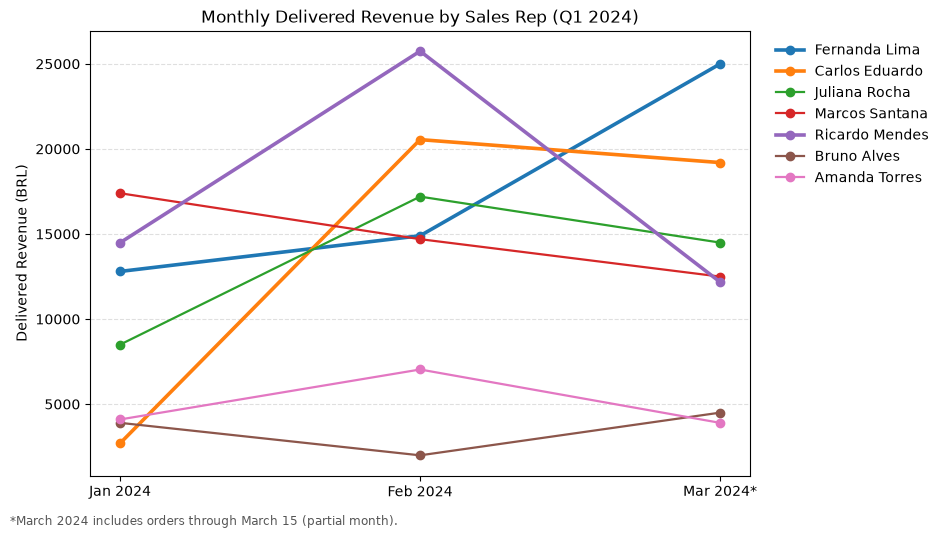

In [11]:
months = ["Jan 2024", "Feb 2024", "Mar 2024*"]
fig, ax = plt.subplots(figsize=(9.5, 5.2))

for _, row in df_monthly.iterrows():
    vals = [row["jan_2024"], row["feb_2024"], row["mar_2024"]]
    lw = 2.6 if row["sales_rep"] in {"Fernanda Lima", "Ricardo Mendes", "Carlos Eduardo"} else 1.6
    ax.plot(months, vals, marker="o", linewidth=lw, label=row["sales_rep"])

ax.set_ylabel("Delivered Revenue (BRL)")
ax.set_title("Monthly Delivered Revenue by Sales Rep (Q1 2024)")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.text(0.01, -0.02, "*March 2024 includes orders through March 15 (partial month).", fontsize=8.5, color="#555555")
fig.tight_layout()
fig.savefig(DOCS_DIR / "monthly_evolution_by_rep.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Action Alert: Sales Reps Below 80% of Target

**Business question:** Who needs an immediate coaching and pipeline action plan?

Uses `GROUP BY ... HAVING` to flag reps whose delivered revenue is below 80% of their monthly target.

In [12]:
sql("""
SELECT
    r.name AS sales_rep,
    r.region,
    COALESCE(SUM(o.total_amount), 0) AS revenue,
    r.monthly_target,
    ROUND(100.0 * COALESCE(SUM(o.total_amount), 0) / r.monthly_target, 1) AS pct_of_monthly_target
FROM sales_reps r
LEFT JOIN orders o
    ON o.sales_rep_id = r.id
    AND o.status = 'Delivered'
GROUP BY r.id, r.name, r.region, r.monthly_target
HAVING ROUND(100.0 * COALESCE(SUM(o.total_amount), 0) / r.monthly_target, 1) < 80
ORDER BY pct_of_monthly_target ASC;
""")

,sales_rep,region,revenue,monthly_target,pct_of_monthly_target
0,Bruno Alves,Center-West,14682.9,35000.0,42.0
1,Amanda Torres,North,19329.0,30000.0,64.4


## Executive Summary & Recommended Actions

1. **Immediate pipeline intervention for Bruno Alves (42.0%) and Amanda Torres (64.4%):** Both reps serve only 2 delivered customers each. Assign outbound B2B/Corporate prospecting goals in Center-West and North, and pair them with top reps for account expansion playbooks.
2. **Audit Carlos Eduardo's high-value cancellations (BRL 13,378.00 lost, 10.7% rate):** Nearly half of TechStore's cancelled revenue comes from 3 orders under Carlos Eduardo. Review payment-method friction (credit card approvals / bank slip expiration) and order follow-up timing before scaling his pipeline further.
3. **Replicate Fernanda Lima's Q1 momentum:** Fernanda nearly doubled her monthly pace by mid-March (BRL 24,994.80) with balanced Corporate + Retail accounts and strong Laptop sales.
4. **Bundle high-margin Accessories into Laptop/Smartphone deals:** Juliana Rocha and Fernanda Lima close high-ticket hardware orders with minimal Accessory attach rates — adding structured Accessory bundles is a fast margin lever.